In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class SupportState(TypedDict):
    query: str
    category: str
    response: str

In [9]:
def analyze_query(state: SupportState):
    query = state["query"].lower()

    if any(word in query for word in ["payment", "bill", "refund", "charge"]):
        category = "billing"

    elif any(word in query for word in ["error", "bug", "crash", "not working"]):
        category = "technical"

    elif any(word in query for word in ["account", "login", "password", "not working"]):
            category = "account"

    else:
        category = "general"

    print(f"Detected category: {category}")

    return {"category": category}

In [15]:
def billing_node(state: SupportState):
    return {
        "response": "Billing support: We can help with payments, refunds, and invoices."
    }


def technical_node(state: SupportState):
    return {
        "response": "Technical support: Let's troubleshoot your issue."
    }


def general_node(state: SupportState):
    return {
        "response": "General support: How can we help you today?"
    }

def account_node(state: SupportState):
    return{
    "response": "Account support: We can help with login and password issues."
}
    

In [16]:
def route_query(state: SupportState):
    category = state["category"]

    if category == "billing":
        return "billing"

    elif category == "technical":
        return "technical"

    elif category == "account":
        return "account"

    else:
        return "general"

In [17]:
builder = StateGraph(SupportState)

# Register nodes
builder.add_node("analyze", analyze_query)
builder.add_node("billing_node", billing_node)
builder.add_node("technical_node", technical_node)
builder.add_node("general_node", general_node)
builder.add_node("account_node", account_node)

# Connect the starting point
builder.add_edge(START, "analyze")

# Add conditional routing
builder.add_conditional_edges(
    "analyze",
    route_query,
    {
        "billing": "billing_node",
        "technical": "technical_node",
        "account": "account_node",
        "general": "general_node"
    }
)

# Connect all branches to the end
builder.add_edge("billing_node", END)
builder.add_edge("technical_node", END)
builder.add_edge("account_node", END)
builder.add_edge("general_node", END)

graph = builder.compile()

In [18]:
queries = [
    "I need a refund for my payment",
    "My application keeps crashing",
    "I want to know more about your services",
    "I cannot log into my account"
]

for query in queries:
    print("\nUser:", query)

    result = graph.invoke({
        "query": query,
        "category": "",
        "response": ""
    })

    print("Category:", result["category"])
    print("Response:", result["response"])


User: I need a refund for my payment
Detected category: billing
Category: billing
Response: Billing support: We can help with payments, refunds, and invoices.

User: My application keeps crashing
Detected category: technical
Category: technical
Response: Technical support: Let's troubleshoot your issue.

User: I want to know more about your services
Detected category: general
Category: general
Response: General support: How can we help you today?

User: I cannot log into my account
Detected category: account
Category: account
Response: Account support: We can help with login and password issues.


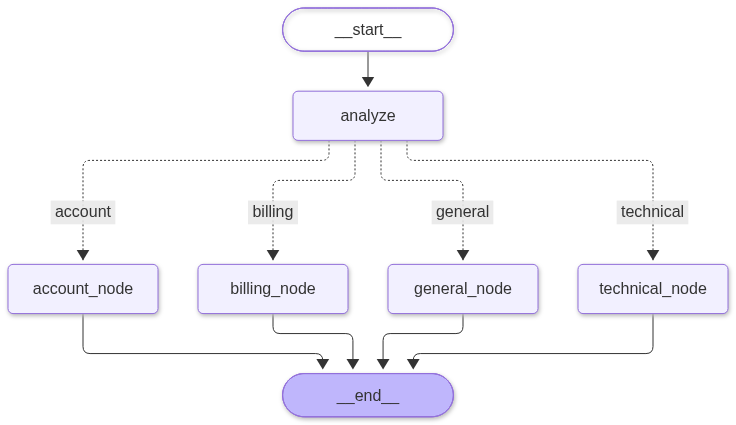

In [19]:
from IPython.display import Image, display

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [20]:
for event in graph.stream(
    {
        "query": "I cannot log into my account",
        "category": "",
        "response": ""
    },
    stream_mode="updates"
):
    print(event)

Detected category: account
{'analyze': {'category': 'account'}}
{'account_node': {'response': 'Account support: We can help with login and password issues.'}}
